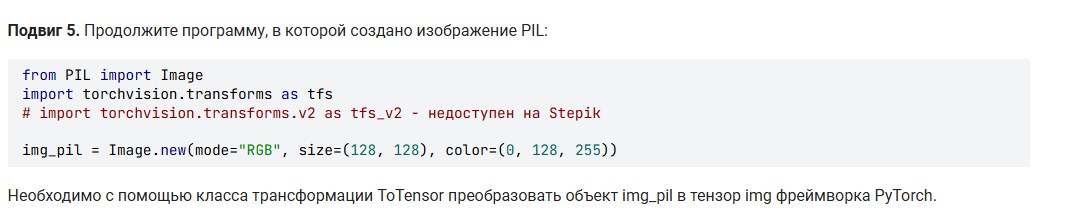

In [1]:
from PIL import Image
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs_v2 - недоступен на Stepik

img_pil = Image.new(mode="RGB", size=(128, 128), color=(0, 128, 255))

# здесь продолжайте программу
to_tensor = tfs.ToTensor()
img  = to_tensor(img_pil)

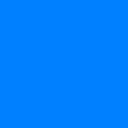

In [6]:
img_pil

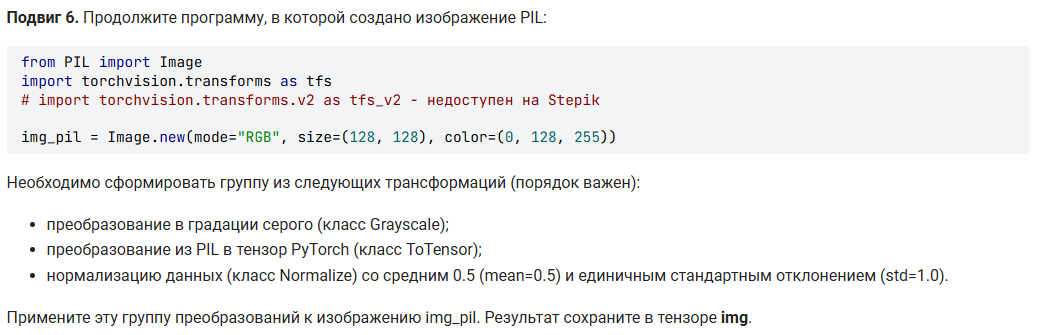

In [12]:
from PIL import Image
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs_v2 - недоступен на Stepik

img_pil = Image.new(mode="RGB", size=(128, 128), color=(0, 128, 255))

# здесь продолжайте программу
transforms = tfs.Compose([tfs.Grayscale(), tfs.ToTensor(), tfs.Normalize(mean=[0.5], std=[1])])
img = transforms(img_pil)
img


tensor([[[-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922],
         [-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922],
         [-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922],
         ...,
         [-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922],
         [-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922],
         [-0.0922, -0.0922, -0.0922,  ..., -0.0922, -0.0922, -0.0922]]])

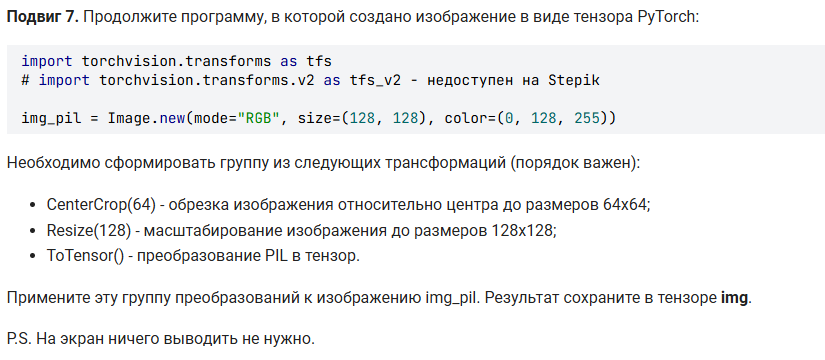

In [13]:
from PIL import Image
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs_v2 - недоступен на Stepik

img_pil = Image.new(mode="RGB", size=(128, 128), color=(0, 128, 255))

# здесь продолжайте программу
transforms = tfs.Compose([tfs.CenterCrop(64), tfs.Resize(128), tfs.ToTensor()])
img = transforms(img_pil)



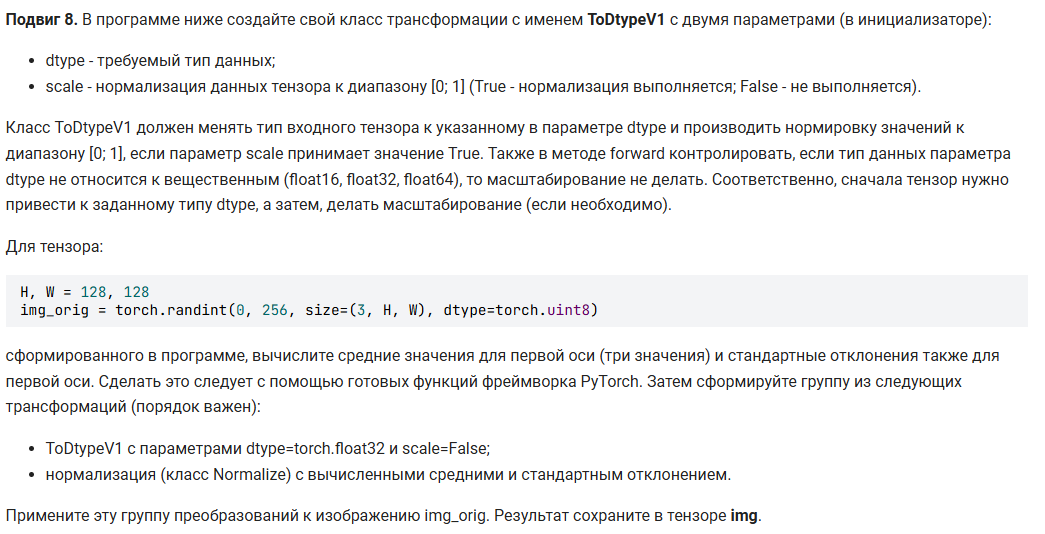

In [4]:
import torch
import torch.nn as nn
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs  # - недоступен на Stepik

# здесь объявляйте класс ToDtypeV1
class ToDtypeV1(nn.Module):
    def __init__(self, dtype, scale: bool=None):
        super().__init__()
        self.dtype = dtype
        self.scale = scale

    def forward(self, item):
        item = item.to(self.dtype)
        if self.dtype in (torch.float16, torch.float32, torch.float64) and self.scale:
            item_min = item.min()
            item_max = item.max()
            item = (item-item_min) / item_max
            
        return item

H, W = 128, 128
img_orig = torch.randint(0, 256, size=(3, H, W), dtype=torch.uint8) # тензор в программе не менять

# img_mean = img_orig.float().mean(axis=[1, 2]).tolist() # средние для каждого цветового канала (первая ось)
# img_std = img_orig.float().std(axis=[1, 2]).tolist() # стандартное отклонение для каждого цветового канала (первая ось)

img_mean = img_orig.float().mean(dim=1).mean(dim=1).tolist() # средние для каждого цветового канала (первая ось)
img_std = img_orig.float().std(dim=1).std(dim=1).tolist() # стандартное отклонение для каждого цветового канала (первая ось)

# здесь продолжайте программу
transforms = tfs.Compose([ToDtypeV1(dtype=torch.float32, scale=False), tfs.Normalize(mean=img_mean, std=img_std)])

img = transforms(img_orig)
img

tensor([[[ -1.1824, -20.6606,  26.1499,  ..., -21.6031, -15.0056,   2.2734],
         [-26.0014, -21.9173,  -1.8107,  ...,  14.8400, -23.1739,  25.8358],
         [ 35.5749, -31.9705,  -6.5232,  ...,  18.6100,  -1.8107,  33.3757],
         ...,
         [ 16.7250,  -4.0099, -34.7980,  ...,  27.4066,   2.5876, -20.6606],
         [-36.9972,   5.1009, -14.3773,  ..., -35.4263, -34.1697, -34.1697],
         [ 21.1233, -19.4039,  15.4683,  ..., -31.0280,   1.0168,  32.4332]],

        [[-40.1862, -42.6623,   7.2138,  ..., -29.2205,  17.1183,  33.7437],
         [ 42.5869, -28.1593,   7.2138,  ...,   8.9825,  32.6825,  17.1183],
         [-15.7787, -12.9489,   0.4929,  ...,   9.6899,   6.5063,  41.1720],
         ...,
         [ 34.8048,  10.7511,  18.1795,  ...,   8.2750,  38.3422,  -9.4116],
         [ 17.4720,   0.8466,  11.1048,  ...,   0.4929,   2.9690,   5.7989],
         [-24.2683,   1.2004,  44.0019,  ...,  -2.3370, -23.2071,  36.2198]],

        [[-13.7678,  13.1041, -27.0379,  ...

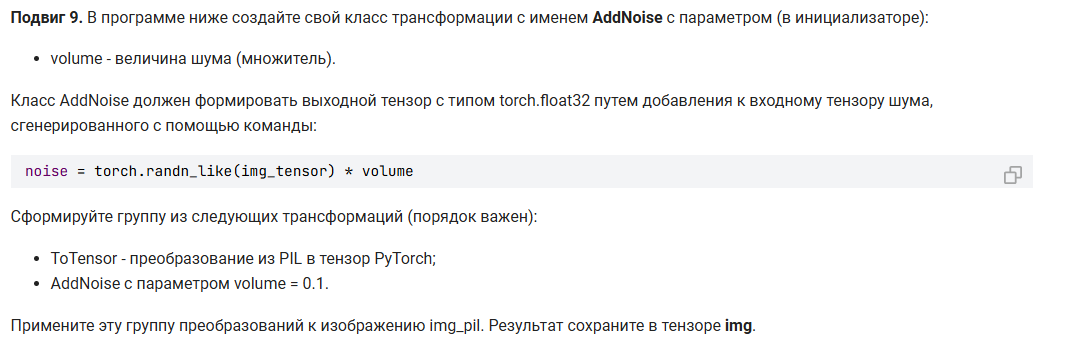

In [11]:
from PIL import Image
import torch
import torch.nn as nn
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs_v2 - недоступен на Stepik

class AddNoise(nn.Module):
    
    def __init__(self, volume):
        super().__init__()
        self.volume = volume

    def forward(self, x):
        x = x.to(torch.float32)
        x += torch.randn_like(x) * self.volume
        return x
        
        
img_pil = Image.new(mode="RGB", size=(128, 128), color=(0, 128, 255))
        
transforms = tfs.Compose([tfs.ToTensor(), AddNoise(volume=0.1)])
img = transforms(img_pil)
img

tensor([[[-0.0349,  0.0288,  0.1663,  ..., -0.2040,  0.0150,  0.2211],
         [-0.1260,  0.1403,  0.0050,  ..., -0.0110, -0.0498,  0.0066],
         [-0.0728, -0.0048, -0.0312,  ...,  0.0628,  0.0122, -0.0443],
         ...,
         [-0.1106, -0.0758, -0.1469,  ..., -0.0426,  0.0464, -0.1017],
         [ 0.0029, -0.0931,  0.0326,  ..., -0.1008, -0.0280,  0.1006],
         [ 0.0334,  0.0596, -0.1120,  ..., -0.0947, -0.1404, -0.0760]],

        [[ 0.5511,  0.6744,  0.5289,  ...,  0.5525,  0.5732,  0.2963],
         [ 0.4747,  0.5301,  0.3203,  ...,  0.3790,  0.4139,  0.7001],
         [ 0.4888,  0.6710,  0.5164,  ...,  0.5066,  0.5165,  0.3645],
         ...,
         [ 0.5737,  0.3943,  0.4337,  ...,  0.6427,  0.5075,  0.6581],
         [ 0.6009,  0.6037,  0.6292,  ...,  0.4079,  0.4404,  0.5715],
         [ 0.5443,  0.5345,  0.6147,  ...,  0.4506,  0.5310,  0.4937]],

        [[ 0.9191,  0.9681,  1.0686,  ...,  1.0287,  1.2083,  1.0072],
         [ 0.9491,  1.0937,  0.9518,  ...,  1

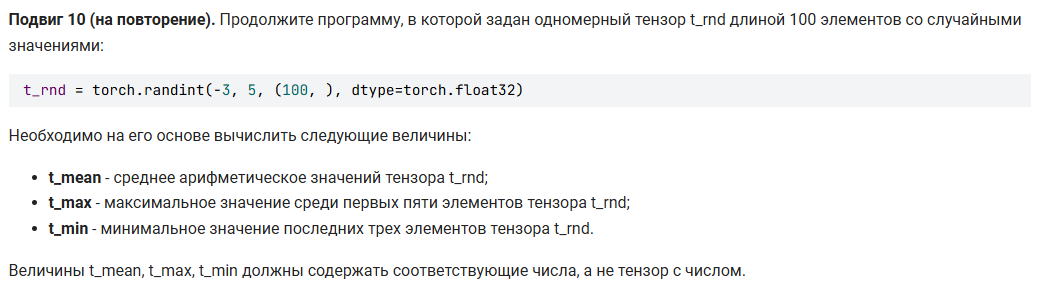

In [15]:
import torch

t_rnd = torch.randint(-3, 5, (100, ), dtype=torch.float32) # значения этого тензора в программе не менять
t_mean = t_rnd.mean().item()
t_max  = t_rnd.max().item()
t_min  = t_rnd.min().item()